# IAAC — Classificação de ataques cibernéticos

Aplicação mínima do roadmap IAAC ao dataset fornecido.

**Autor:** Guilherme Jesus · **Turma:** 2.º Ciber

**Âmbito:** componente individual dedicada apenas ao CSV de ciberataques. Os resultados não incluem os outros datasets do grupo, que serão integrados mais tarde no repositório comum. O alvo é `attack_type`: Normal, DDoS, PortScan ou BruteForce. Projeto académico; não validado para uso operacional.

O repositório do colega foi usado apenas como referência de estrutura. Os dados, análises e resultados deste notebook pertencem exclusivamente a esta componente individual.

## 1. Business understanding

Objetivo: classificar registos de tráfego a partir de seis atributos. As métricas principais são macro-F1 e recall por classe, porque os erros por tipo de ataque importam. Não foram fornecidos custos dos erros, contexto temporal nem origem detalhada do dataset.

## 2. Data understanding

O CSV tem 100.000 linhas, seis atributos e um alvo. A inspeção encontrou zero nulos, uma linha duplicada e quatro classes quase equilibradas. As relações entre atributos e alvo parecem muito determinísticas; ver a análise de limitações no fim.

Dimensão: (100000, 7)
Valores ausentes: 0
Duplicados exatos: 1


,duration,src_bytes,dst_bytes,packet_count,protocol,failed_logins,attack_type
0,1,8605,418,631,TCP,0,DDoS
1,1,499,148,131,UDP,0,PortScan
2,10,370,160,105,UDP,0,PortScan
3,2,5138,320,666,TCP,0,DDoS
4,36,524,467,58,UDP,10,BruteForce


,contagem
attack_type,
DDoS,25077
BruteForce,25039
PortScan,25008
Normal,24876


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
duration,100000.0,NaN,NaN,NaN,16.46272,15.632207,1.0,4.0,10.0,28.0,60.0
src_bytes,100000.0,NaN,NaN,NaN,2219.6287,2751.14241,50.0,341.0,781.0,3024.0,10000.0
dst_bytes,100000.0,NaN,NaN,NaN,426.17103,466.528205,20.0,131.0,256.0,458.0,2000.0
packet_count,100000.0,NaN,NaN,NaN,202.55077,249.729802,5.0,37.0,87.0,257.0,1000.0
protocol,100000,2,TCP,50186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
failed_logins,100000.0,NaN,NaN,NaN,1.63052,3.045577,0.0,0.0,0.0,3.0,10.0
attack_type,100000,4,DDoS,25077,NaN,NaN,NaN,NaN,NaN,NaN,NaN


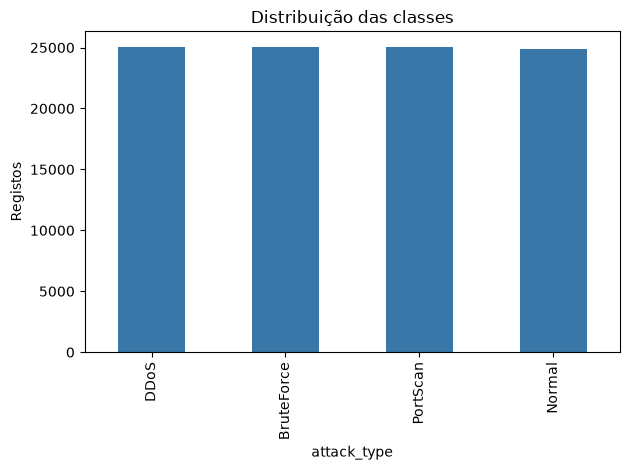

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
DATA = PROJECT / 'data' / 'cyber_attack_dataset_100000.csv'
df = pd.read_csv(DATA)
print('Dimensão:', df.shape)
print('Valores ausentes:', int(df.isna().sum().sum()))
print('Duplicados exatos:', int(df.duplicated().sum()))
display(df.head())
display(df['attack_type'].value_counts().rename('contagem').to_frame())
display(df.describe(include='all').T)
df['attack_type'].value_counts().plot.bar(title='Distribuição das classes', color='#3977a8')
plt.ylabel('Registos'); plt.tight_layout(); plt.show()

## 3. Data preparation e modelação

O pipeline atualizado remove a cópia duplicada, separa treino/teste de forma estratificada, codifica `protocol`, escala os valores numéricos dentro dos pipelines e compara baseline, regressão logística, árvore, k-NN, Naive Bayes, SVM linear, Random Forest e XGBoost. A escolha é feita no treino por validação cruzada; o teste retido é usado no final.

=== BUSINESS E DATA UNDERSTANDING ===
Problema: classificar tráfego como Normal, DDoS, PortScan ou BruteForce.
Uso: aprendizagem/triagem; não é um sistema validado para produção.
Dimensão original: (100000, 7)
Linhas duplicadas removidas: 1
Dimensão após limpeza: (99999, 7)
Tipos e nulos:
                 tipo  nulos
duration       int64      0
src_bytes      int64      0
dst_bytes      int64      0
packet_count   int64      0
protocol         str      0
failed_logins  int64      0
attack_type      str      0
Estatísticas:
                  count unique   top   freq         mean         std   min  \
duration       99999.0    NaN   NaN    NaN    16.462865   15.632218   1.0   
src_bytes      99999.0    NaN   NaN    NaN  2219.648206  2751.14925  50.0   
dst_bytes      99999.0    NaN   NaN    NaN   426.173602  466.529829  20.0   
packet_count   99999.0    NaN   NaN    NaN   202.552036   249.73073   5.0   
protocol         99999      2   TCP  50186          NaN         NaN   NaN   
failed_l

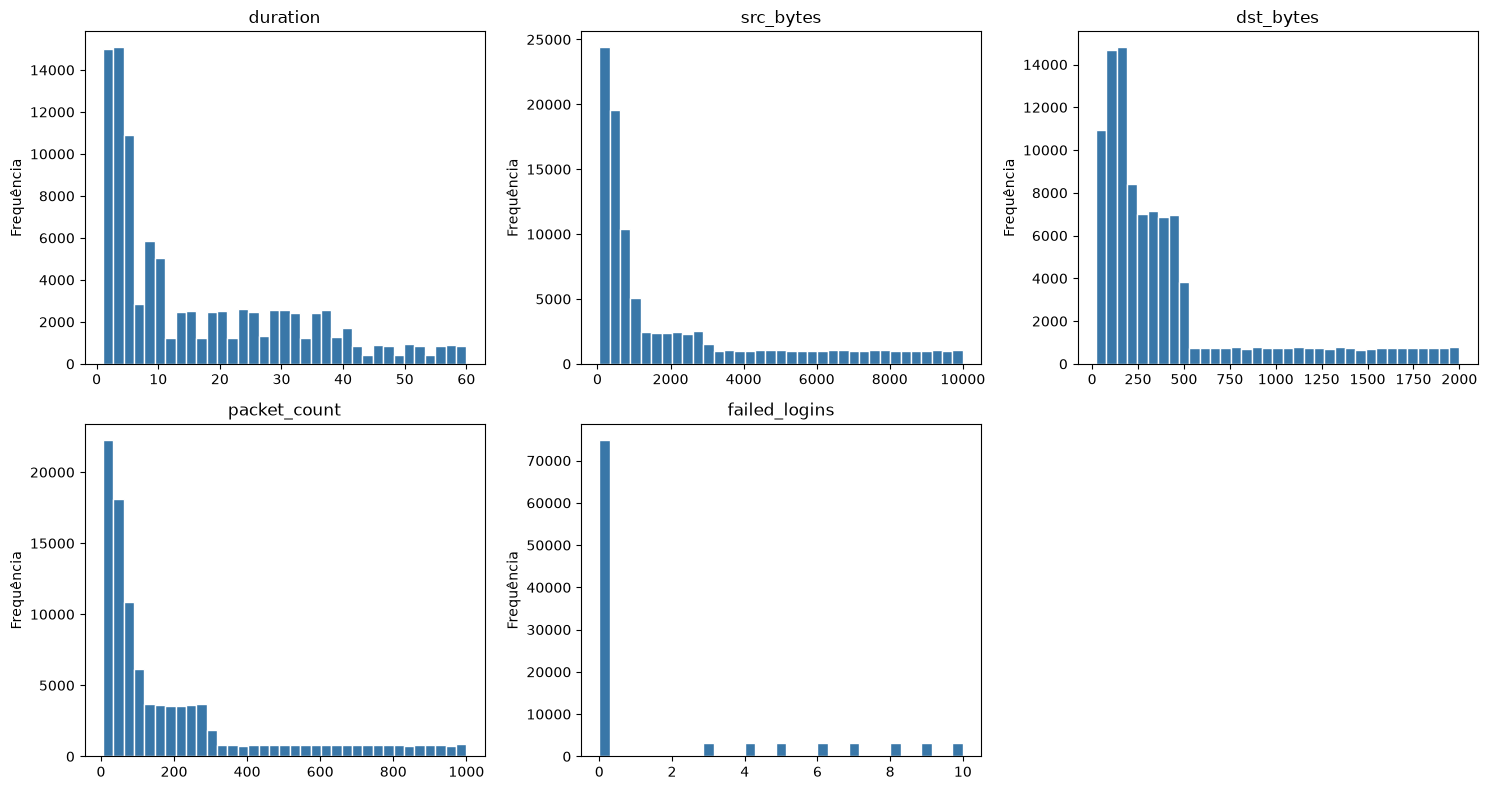

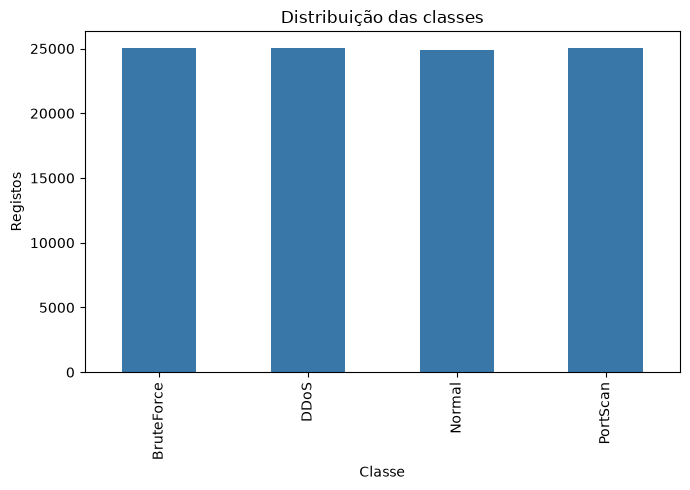

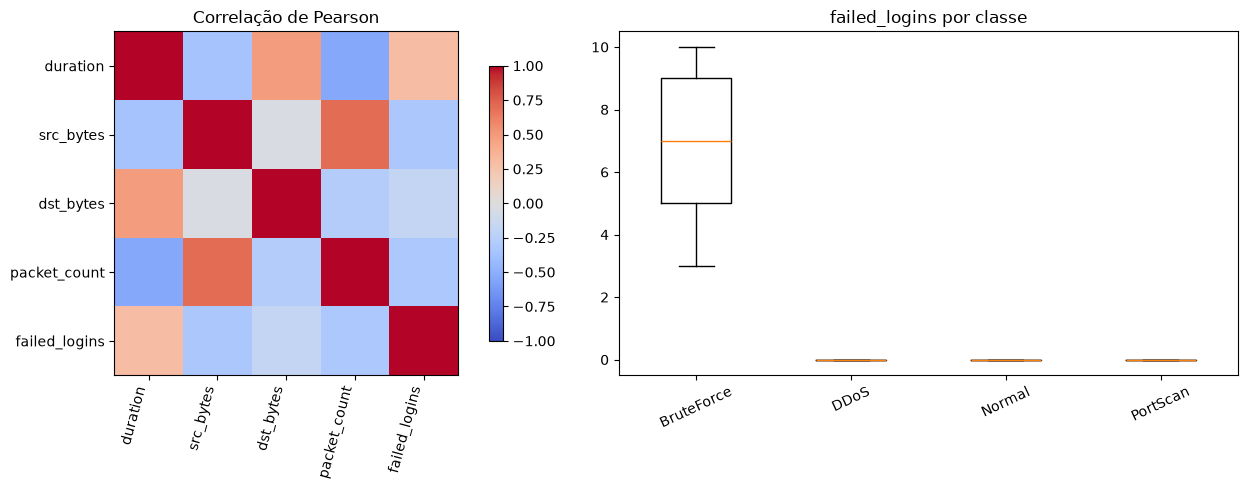

Nota: verificar se atributos/categorias codificam diretamente o rótulo; o resultado anterior foi quase perfeito.
=== DATA PREPARATION ===
Treino: 79,999; teste retido: 20,000
Classes quase equilibradas; não é aplicada reamostragem.
=== CLASSIFICAÇÃO E VALIDAÇÃO CRUZADA ===


              modelo  macro-F1 médio  desvio macro-F1  accuracy média
       Random Forest          1.0000           0.0000          1.0000
             XGBoost          1.0000           0.0000          1.0000
   Árvore de decisão          1.0000           0.0000          1.0000
                k-NN          0.9997           0.0001          0.9997
          SVM linear          0.9997           0.0001          0.9997
 Regressão logística          0.9994           0.0002          0.9994
Gaussian Naive Bayes          0.8062           0.0023          0.8239
            Baseline          0.1002           0.0000          0.2508
=== AJUSTE DA ÁRVORE E SELEÇÃO PELO TREINO ===


Vencedor CV inicial: Random Forest (1.0000)
Melhor árvore ajustada CV: 1.0000 {'model__min_samples_leaf': 2, 'model__max_depth': None, 'model__criterion': 'gini'}
Modelo final selecionado: Random Forest (macro-F1 CV=1.0000)
Macro-F1 treino: 1.0000; teste: 1.0000; diferença: 0.0000
Accuracy teste: 1.0000; macro-F1 teste: 1.0000
Precision, recall e F1 por classe:
               precision    recall  f1-score   support

  BruteForce     1.0000    1.0000    1.0000      5008
        DDoS     1.0000    1.0000    1.0000      5016
      Normal     1.0000    1.0000    1.0000      4975
    PortScan     1.0000    1.0000    1.0000      5001

    accuracy                         1.0000     20000
   macro avg     1.0000    1.0000    1.0000     20000
weighted avg     1.0000    1.0000    1.0000     20000

ROC-AUC macro OvR teste: 1.0000


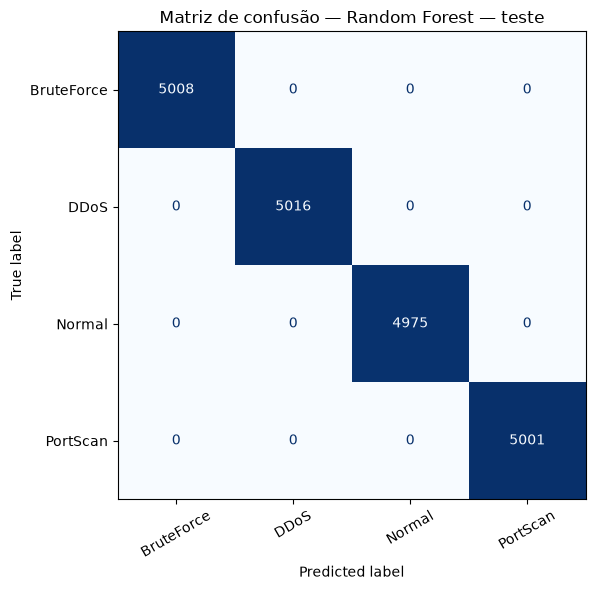

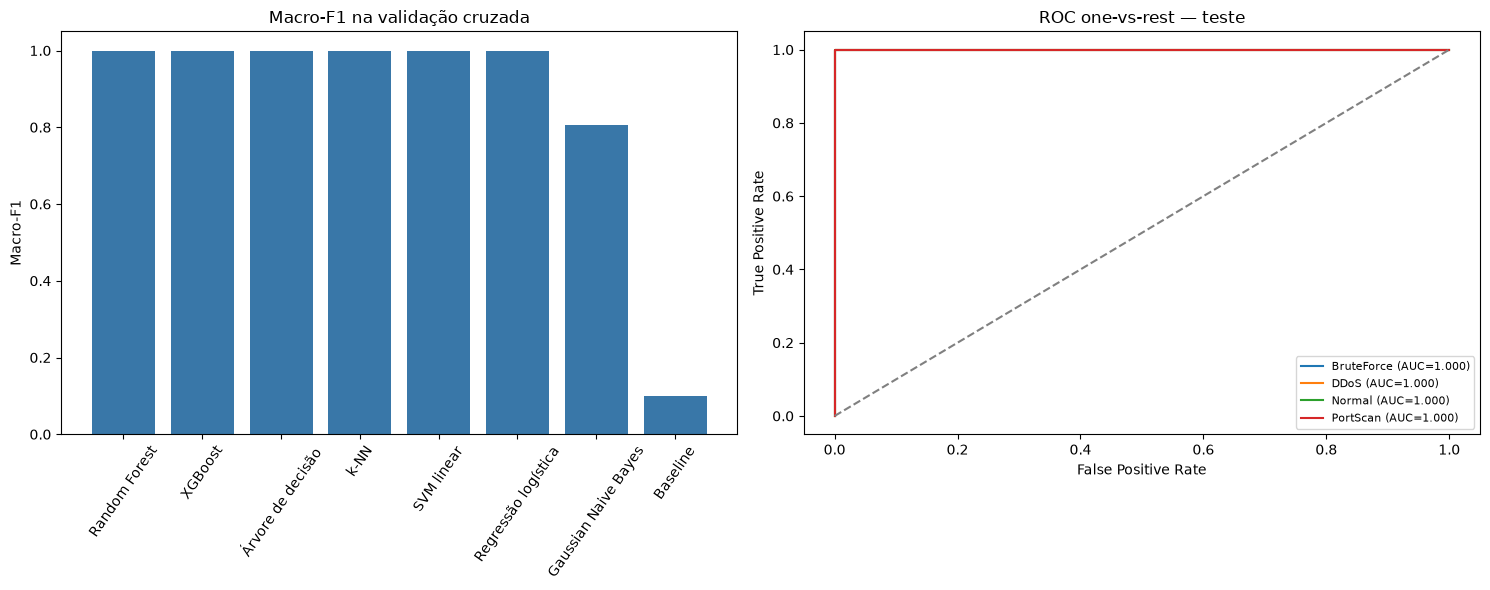

Gráficos, resumo e modelo guardados em: C:\Users\Darkgui\Downloads\IAAC_Cyber_Attacks\resultados
Limitação: split aleatório pressupõe independência; sem timestamp/ID não se testa generalização por período/sessão.
Outliers potenciais são assinalados, não removidos automaticamente sem justificação do domínio.


{'__name__': '__main__',
 '__doc__': 'Aplicação mínima IAAC ao dataset de ataques cibernéticos.\nUso: py iaac_minimum_apply.py [caminho do CSV]\nRequisitos: py -m pip install -r requirements.txt\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'C:\\Users\\Darkgui\\Downloads\\IAAC_Cyber_Attacks\\iaac_minimum_apply.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_

In [2]:
import runpy, sys
script = PROJECT / 'iaac_minimum_apply.py'
sys.argv = [str(script)]
runpy.run_path(str(script), run_name='__main__')

## 4. Resultados e interpretação

Execução registada: Random Forest venceu a validação cruzada (macro-F1 ≈ 1,0000). No teste de 20.000 registos, accuracy, macro-F1 e ROC-AUC macro OvR foram 1,0000; todas as classes tiveram precision, recall e F1 de 1,0000. A matriz de confusão e os gráficos são gravados em `resultados/graficos/`; métricas em `resultados/resumo_resultados.json`.

**Limitação crítica:** no dataset, todos os DDoS usam TCP e todos os BruteForce usam UDP; `failed_logins` também separa BruteForce das outras classes. Isso pode explicar os scores perfeitos e sugere que os rótulos podem ter sido construídos a partir dos atributos. Confirmar a origem e avaliar noutro conjunto antes de alegar generalização para tráfego real.

## 5. Ficheiros de apoio

- `../docs/GUIA_SIMPLES.md`: explicação para apresentação.
- `../docs/RESULTADOS.md`: comparação e métricas detalhadas.
- `../docs/BACKLOG.md`: user stories, sprints, branches e templates Scrum.
- `../docs/REGISTO_TRABALHO.md`: registo técnico do projeto.
- `../data/README.md`: descrição/proveniência dos dados.
### Gráficos da execução

![Comparação de macro-F1 e curvas ROC](../resultados/graficos/comparacao_e_roc.png)

![Matriz de confusão do Random Forest](../resultados/graficos/matriz_confusao_teste.png)

![Resumo visual da EDA](../resultados/graficos/eda_resumo.svg)
